# Homework 2

In [1]:
%matplotlib inline
import numpy as np
from matplotlib import pyplot as plt
import math

## Problem 1
1) Back in the day before calculator has square root function. People use the "divide and average" method to calculate $\sqrt{a}$ where $a$ is a postive number. The method goes

 - Start with a number $x_0$, then the next guess for $a$ can be obtained by

$\displaystyle
x_{n+1} = \frac{x_n + a/x_n}{2}
$

 - Then you repeat and keep making the next guess.


1.1) Calculate $\sqrt{17}$ using this method. Pick a sensible value for $x_0$ and do it for 5 iterations.

In [2]:
# say we program our sqrt(a) finder to use x_0 such that x_0^2 < a
A = 17
x = 4
print(x)

for _ in range(5):
    x = (x + A/x)/2
    print(x)

4
4.125
4.1231060606060606
4.123105625617684
4.123105625617661
4.123105625617661


In [3]:
x**2

17.0

1.2) Show that this method is equivalent to Newton's method. Hint find equation where the answer is sqrt.

let

$$
f(x)=x^2-a
$$

then

$$
\frac{df(x)}{dx}=2x
$$

for newton's method, the next guess is traced from the tangent slope of $f(x)$ towards x-axis, which the tangent line can be written with point-slope form for a line $\left(y-y_0=m(x-x_0)\right)$ as

$$
y-f(x_0)=\text{\{slope\}}(x-x_0)
$$

we're finding x-intercepts, we set $y=0$, and the slope is described with $\frac{df(x_0)}{dx}$,

$$
0-f(x_0)=\frac{df(x_0)}{dx}(x-x_0)
$$

and therefore,

$$
x=x_0-\frac{f(x_0)}{\frac{df(x_0)}{dx}}
$$

then substitute $f(x)$ and $\frac{df(x)}{dx}$ value in

$$
x=x_0-\frac{x_0^2-a}{2x_0}
$$

combine the terms,

$$
x=\frac{2x_0^2-(x_0^2-a)}{2x_0}
$$

$$
x=\frac{x_0^2+a}{2x_0}
$$

and split the fraction,

$$
x=\frac12\left(x_0+\frac{a}{x_0}\right)
$$

so, for repeated iteration,

$$
\boxed{
x_{n+1}=\frac{x_n+a/x_n}{2}
}
$$

<!-- QED. -->
<div style="text-align: right;">■</div>

1.3) Find an equivalent formula for finding cube root ($\sqrt[3]{a}$)

$x_{n+1} =  H(x_n)$

Find $H(x_n)$

let

$$
f(x)=x^3-a
$$

then

$$
\frac{df(x)}{dx}=3x^2
$$

for newton's method, the next guess is traced from the tangent slope of $f(x)$ towards x-axis, which the tangent line can be written with point-slope form for a line ($y-y_0=m(x-x_0)$) as

$$
y-f(x_0)=\text{\{slope\}}(x-x_0)
$$

we're finding x-intercepts, we set $y=0$, and the slope is described with $\frac{df(x_0)}{dx}$,

$$
0-f(x_0)=\frac{df(x_0)}{dx}(x-x_0)
$$

and therefore,

$$
x=x_0-\frac{f(x_0)}{\frac{df(x_0)}{dx}}
$$

then substitute $f(x)$ and $\frac{df(x)}{dx}$ value in

$$
x=x_0-\frac{x_0^3-a}{3x_0^2}
$$

combine the terms,

$$
x=
\frac{3x_0^3-(x_0^3-a)}{3x_0^2}
$$

$$
x=
\frac{2x_0^3+a}{3x_0^2}
$$

and split the fraction,

$$
x=
\frac13\left(2x_0+\frac{a}{x_0^2}\right)
$$

so, for repeated iteration,

$$
x_{n+1}
=
\frac13\left(2x_n+\frac{a}{x_n^2}\right)
$$

therefore,

$$
\boxed{
H(x_n)=\frac{2x_n+a/x_n^2}{3}
}
$$

In [4]:
def H1(x: float, a: float) -> float:
    return (2*x + a / (x*x))/3

1.4) Use the above method to find $\sqrt[3]{17}$

In [5]:
# using the same conventional (that i made up) for guessing the initial value, 
# 2^3 = 8, and 3^3 = 27, so we start with x_0 = 2
x = 2
print(x)

for _ in range(5):
    x = H1(x, A) 
    print(x)

2
2.75
2.5826446280991733
2.571331512066116
2.571281591627434
2.5712815906582356


In [6]:
x**3

17.000000000000004

## Problem 2

Here is another numerical differentiation method (the error term is $O(h^2)$).

$\displaystyle
f'(x) = \frac{-f(x+2h)+4f(x+h)-3f(x)}{2h} + O(h^2)
$



In [7]:
def df2(f, x, h):
    return (-f(x + 2 * h) + 4 * f(x + h) - 3 * f(x)) / (2 * h)

2.1) Let $f(x) = xe^{-x}$. Use the above formula to find the "first" derivative of $f(x)$ and plot the first derivative for $x \in [0,1]$. Pick appropriate value for $h$.

In [8]:
def f2(x): 
    return x * np.exp(-x)

supposed that we can't find this function's derivative analytically, test with a few values in the range of $[0, 1]$

In [9]:
tolerance = 1e-14

h = 0.125
x = np.linspace(0, 1, 1 << 3)

while(True): 
    y1 = df2(f2, x, h)
    y2 = df2(f2, x, h / 2)

    if (np.max(np.abs(y1 - y2)) < tolerance): 
        break

    h /= 2

print(h)

6.938893903907228e-18


at tolerance of $10^-14$ (the usual tight tolerance for double precision float i assume), the suggested h for this function of this bound is $6.938893903907228e-18$, which is too small for double precision float to handle. i supposed rounding would dominate in this case and we loss accuracy. So, we drop down the tolerance 

In [10]:
tolerance = 1e-10

h = 0.125
x = np.linspace(0, 1, 1 << 3)

while(True): 
    y1 = df2(f2, x, h)
    y2 = df2(f2, x, h / 2)

    if (np.max(np.abs(y1 - y2)) < tolerance): 
        break

    h /= 2

print(h)

7.62939453125e-06


In [11]:
h2 = 7.62939453125e-06

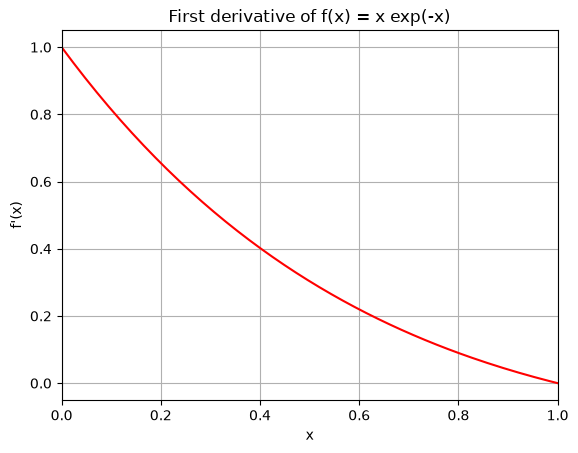

In [12]:
x = np.linspace(0, 1, 1 << 7)
y = df2(f2, x, h2)

plt.plot(x, y, color='red')
plt.title("First derivative of f(x) = x exp(-x)")
plt.xlabel("x")
plt.ylabel("f'(x)")
plt.xlim(0, 1)
plt.grid(True)
plt.show()

2.2) Let $f(x) = xe^{-x}$. Use the formula in 2.1) to find the "second" derivative of $f(x)$ and plot the second derivative for $x \in [0,1]$

second derivative could be derived from first derivative, we could use the center differentiate formula

$$
    f'(x) \approx \frac{f(x+h)-f(x-h)}{2h}
$$

or, a better approach in this case might be to just plug that `df2(f, x, h)` function into itself

In [13]:
def ddf2(f, x, h):
    def df(t):
        return df2(f, t, h)

    return df2(df, x, h)

would the optimal `h` change? 

In [14]:
tolerance = 1e-10

h = 0.125
x = np.linspace(0, 1, 1 << 3)

while(True): 
    y1 = ddf2(f2, x, h)
    y2 = ddf2(f2, x, h / 2)

    if (np.max(np.abs(y1 - y2)) < tolerance): 
        break

    h /= 2

print(h)

6.938893903907228e-18


`h` does change, for the same tolerance value

In [15]:
tolerance = 1e-8

h = 0.125
x = np.linspace(0, 1, 1 << 3)

while(True): 
    y1 = ddf2(f2, x, h)
    y2 = ddf2(f2, x, h / 2)

    if (np.max(np.abs(y1 - y2)) < tolerance): 
        break

    h /= 2

print(h)

6.938893903907228e-18


In [16]:
tolerance = 1e-7

h = 0.125
x = np.linspace(0, 1, 1 << 3)

while(True): 
    y1 = ddf2(f2, x, h)
    y2 = ddf2(f2, x, h / 2)

    if (np.max(np.abs(y1 - y2)) < tolerance): 
        break

    h /= 2

print(h)

0.0001220703125


it seems like the estimation calculation collapse at $10^{-8}$, so we take the tolerance of $10^{-7}$, and the `h` value would be $0.0001220703125$

In [17]:
h2 = 0.0001220703125

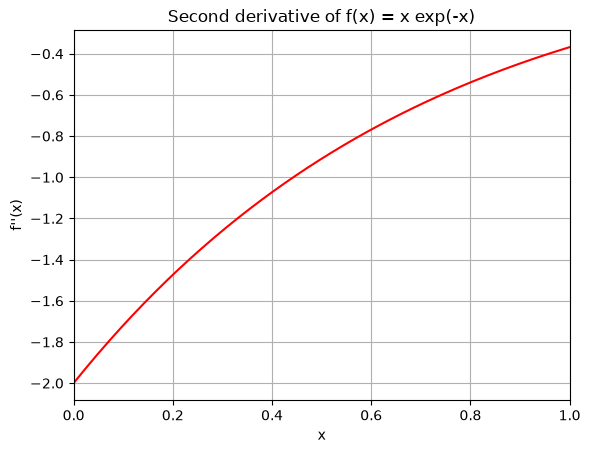

In [18]:
x = np.linspace(0, 1, 1 << 7)
y = ddf2(f2, x, h2)

plt.plot(x, y, color='red')
plt.title("Second derivative of f(x) = x exp(-x)")
plt.xlabel("x")
plt.ylabel("f''(x)")
plt.xlim(0, 1)
plt.grid(True)
plt.show()

## Problem 3

Notice that $\arctan(1) = \pi/4$ , this means we can calculate $\pi$ by using $4 \times \arctan(1)$

So this means that if we find Taylor series expansion of $\arctan(x)$ around $x=0$, then we can calculate $\pi$ to any accuracy we want.

3.1) Find taylor expansion of $\arctan$ for 3 **non-zero** terms. If you forgot,
$$
\frac{d}{dx} \arctan(x) = \frac{1}{1+x^2}
$$

In [19]:
4 * np.arctan(1)

np.float64(3.141592653589793)

Let $g(x)=\dfrac{1}{1+x^2}=(1+x^2)^{-1}$, so that $\dfrac{d}{dx}\arctan(x)=g(x)$. Find the derivative

\begin{align*}
g'(x)
&= -(1+x^2)^{-2}(2x) \\
&= -\frac{2x}{(1+x^2)^2}, \\[6pt]
g''(x)
&= -2(1+x^2)^{-2}+8x^2(1+x^2)^{-3} \\
&= \frac{-2(1+x^2)+8x^2}{(1+x^2)^3}
= \frac{6x^2-2}{(1+x^2)^3}, \\[6pt]
g^{(3)}(x)
&= 12x(1+x^2)^{-3}-6x(6x^2-2)(1+x^2)^{-4} \\
&= \frac{12x(1+x^2)-6x(6x^2-2)}{(1+x^2)^4}
= \frac{24x(1-x^2)}{(1+x^2)^4}, \\[6pt]
g^{(4)}(x)
&= 24(1-3x^2)(1+x^2)^{-4}-192x^2(1-x^2)(1+x^2)^{-5} \\
&= \frac{24(1-3x^2)(1+x^2)-192x^2(1-x^2)}{(1+x^2)^5} \\
&= \frac{24(1-10x^2+5x^4)}{(1+x^2)^5}, \\[6pt]
g^{(5)}(x)
&= 24(-20x+20x^3)(1+x^2)^{-5}-240x(1-10x^2+5x^4)(1+x^2)^{-6} \\
&= \frac{24(-20x+20x^3)(1+x^2)-240x(1-10x^2+5x^4)}{(1+x^2)^6} \\
&= -\frac{240x(3-10x^2+3x^4)}{(1+x^2)^6}.
\end{align*}

as the question request for taylor expansion at x about 0, we use maclaurin series of 

$$
    g(x) = \sum_{k=0}^{n} \frac{g^{(k)}(0)}{k!}x^k + O(x^{n+1})
    = g(0) + g'(0)x + \frac{g''(0)}{2!}x^2 + \cdots
    + \frac{g^{(n)}(0)}{n!}x^n + O(x^{n+1}).
$$

$$
    \begin{aligned}
    g(0) &= \arctan(0)=0, \\
    g'(0) &= \frac{1}{1+0^2}=1, \\
    g''(0) &= -\frac{2(0)}{(1+0^2)^2}=0, \\
    g^{(3)}(0) &= \frac{6(0)^2-2}{(1+0^2)^3}=-2, \\
    g^{(4)}(0) &= \frac{24(0)(1-0^2)}{(1+0^2)^4}=0, \\
    g^{(5)}(0) &= \frac{24(1-10(0)^2+5(0)^4)}{(1+0^2)^5}=24 = 2 \times 3 \times 4.
    \end{aligned}
$$

$$
    \begin{aligned}
    f(x)
    &= g(0)+g'(0)x+\frac{g''(0)}{2!}x^2
    +\frac{g^{(3)}(0)}{3!}x^3
    +\frac{g^{(4)}(0)}{4!}x^4
    +\frac{g^{(5)}(0)}{5!}x^5+O(x^6) \\
    &= 0+(1)x+\frac{0}{2!}x^2
    +\frac{-2}{3!}x^3
    +\frac{0}{4!}x^4
    +\frac{24}{5!}x^5+O(x^6) \\
    \end{aligned}
$$

$$
    \begin{aligned}
    \arctan(x)
    &= \boxed{x-\frac{x^3}{3}+\frac{x^5}{5}}-\cdots
    +\frac{(-1)^{n-1}x^{2n-1}}{2n-1}
    +O(x^{2n+1})
    \end{aligned}
$$

3.2) Guess the rest of the terms

$$ \boxed{\sum_{k=0}^{n-1}\frac{(-1)^k x^{2k+1}}{2k+1}+O(x^{2n+1}), \qquad x\to 0}$$

3.3) Calculate $\pi$ using taylor approximation for 200 **non-zero** terms. (you must write some sort of for loop to do it).

In [20]:
x = 1

sum = 0.0

for k in range(200):
    # sum += ((-1)**k * x**(2*k+1)) / (2*k + 1)
    # optimize it a bit
    sum += (-1 if (k & 1) == 1 else 1) / (2*k + 1)

pi = 4*sum
print(pi)

3.136592684838816


with residual of

In [21]:
print(np.pi - pi)

0.004999968750976969


try test it with `np.arctan()`, turns out it's very accurate (or at least match `np.pi` value) in this case

In [22]:
print(np.pi - 4 * np.arctan(1))

0.0


## Problem 4

4) The purpose of this problem is to make sure you know that the bound on $f^{(n+1)}(\xi)$ after all the cancellation is **NOT** necessarily 1 **NOR** does it have to look the same as the next term in the series.

4.1)Find the first 3 **non-zero** terms of Taylor series for
$$f(x) = \frac{1}{1-x}$$



let

$$
f(x)=\frac{1}{1-x}=(1-x)^{-1}
$$

then

\begin{align*}
f'(x)
&= -(1-x)^{-2}(-1)
= \frac{1}{(1-x)^2}, \\[6pt]
f''(x)
&= -2(1-x)^{-3}(-1)
= \frac{2}{(1-x)^3}, \\[6pt]
f^{(3)}(x)
&= -6(1-x)^{-4}(-1)
= \frac{6}{(1-x)^4}.
\end{align*}

we use maclaurin series of

$$
f(x)=\sum_{k=0}^{n}\frac{f^{(k)}(0)}{k!}x^k+O(x^{n+1})
= f(0)+f'(0)x+\frac{f''(0)}{2!}x^2+\cdots
+\frac{f^{(n)}(0)}{n!}x^n+O(x^{n+1}).
$$

$$
\begin{aligned}
f(0)&=\frac{1}{1-0}=1, \\
f'(0)&=\frac{1}{(1-0)^2}=1, \\
f''(0)&=\frac{2}{(1-0)^3}=2, \\
f^{(3)}(0)&=\frac{6}{(1-0)^4}=6.
\end{aligned}
$$

$$
\begin{aligned}
f(x)
&=f(0)+f'(0)x+\frac{f''(0)}{2!}x^2
+\frac{f^{(3)}(0)}{3!}x^3+O(x^4) \\
&=1+(1)x+\frac{2}{2!}x^2+\frac{6}{3!}x^3+O(x^4) \\
&=1+x+x^2+x^3+O(x^4).
\end{aligned}
$$

$$
f^{(k)}(x)=\frac{k!}{(1-x)^{k+1}}
\quad\Rightarrow\quad
\frac{f^{(k)}(0)}{k!}=1.
$$

$$
\frac{1}{1-x}=\boxed{1+x+x^2}+x^3+\cdots
=\sum_{k=0}^{\infty}x^k,\qquad |x|<1.
$$

4.2) If we estimate $$\frac{1}{0.8} = \frac{1}{1-0.2}$$ using the first 3 non-zero terms, what is the bound on the truncation error. Be careful about evaluating the bound for $f^{(n+1)}({\xi})$.

$\frac{1}{0.8} = \frac{1}{1 - 0.2} = 1 + 0.2 + 0.2^2 + O(x^3)$

In [23]:
1/0.8 - (1 + 0.2 + 0.2*0.2)

0.010000000000000009

So, our real truncation error is $0.01$. Now, using the given formula for error bound (from the lecture notes), 

$$
|R_n(x)| \leq \frac{M}{(n+1)!} |x-a|^{n+1}
$$

as $f^{(3)}(x) = \frac{6}{{(1-x)^4}}$, our upper bound $M$ of the third derivative on the range of $[0.0, 0.2]$ is $\frac{6}{(1-0.2)^4} = \frac{6}{0.8^4}$we got

$$
R_2 (0.2) \leq \left(\frac{\frac{6}{0.8^4}}{(2+1)!}\right) |0.2-0|^{2+1}
$$

In [24]:
(6/0.8**4)/ math.factorial(3) * abs(0.2 - 0)**(2 + 1)

0.01953125

which our actual error is within the bound $|R_2 {(0.2)}| = 0.01 \leq 0.01953125)$, so i guess the bound is valid. 

4.3) How many terms do wee need to calculate $1/(1-0.2)$ such that the uncertainty is less than 10e-5.

we have to find $R_n (0.2) \leq 10^-5$, 

$$
R_n (0.2) \leq \left(\frac{\frac{(n+1)!}{0.8^{(n + 2)}}}{(n+1)!}\right) |0.2-0|^{n+1} 
= \left(\frac{1}{0.8^{(n + 2)}}\right) |0.2-0|^{n+1} \leq 10^{-5}
$$

let 

$$f(x) = \left(\frac{1}{0.8^{(n + 2)}}\right) |0.2-0|^{n+1} - 10^{-5}$$

In [25]:
def f4(n): 
    return (1/0.8**(n+2)) * abs(0.2 - 0)**(n+1) - 1e-5

then we find $n$ that satisfied the uncertainty bound, with basic loop

In [26]:
n = 0

while(True):
    if (f4(n) <= 0): 
        break

    n += 1

print(n)

8


$|R_8 (0.2)| \leq 10^{-5}$, we got the highest polynomial term of degree 8, so it's up to the 9th term of taylor's expansion

In [27]:
sum = 0.0

for i in range(9):
    sum += (0.2)**i

print(sum)

1.2499993600000001


In [28]:
1/(1-0.2)

1.25

In [29]:
abs(1/(1-0.2) - sum)

6.399999998851769e-07

## Problem 5

The goal of this problem is to turn Mario(`mario.png`) into Luigi(`luigi.png`).

<img src="mario.png" style="display:inline; width:200px;"/>
<img src="luigi.png" style="display:inline; width:200px;"/>

If you can accomplish this by other algorithm, do it! you don't need to follow my guide. Just make a picture that looks like `luigi.png`. Depise having written a lengthy guide, I actually encourage you to *not* follow my guide, but to improvise and be creative. If you know what to do , you can do this in less than 20 lines.

### Luigination Guide

This problem will show you how to approach a seemingly impossible and wtf-ish problem.

When you read this guide, I want you to think not only about how to do it but how to figure out how to do it, which is way more important.

To accomplish the *Luigination* we need to do two things.

 1) Detect his cloth and hat which is defined by its *redness*.
 
 2) Changing the color from red to green without changing the *shade*.
 
**Tips:** Look up numpy array slicing it will make you code much easier to read.

For my initial solution before diving into the problem, we use one 'red' pixel from `mario.png` as an anchor by comparing it's RGB value to the same pixel (but 'green) from `luiji.png`, then add their RGB difference to every detected 'red' pixel.

Initial transformation — Mean absolute RGB error: 0.01326173


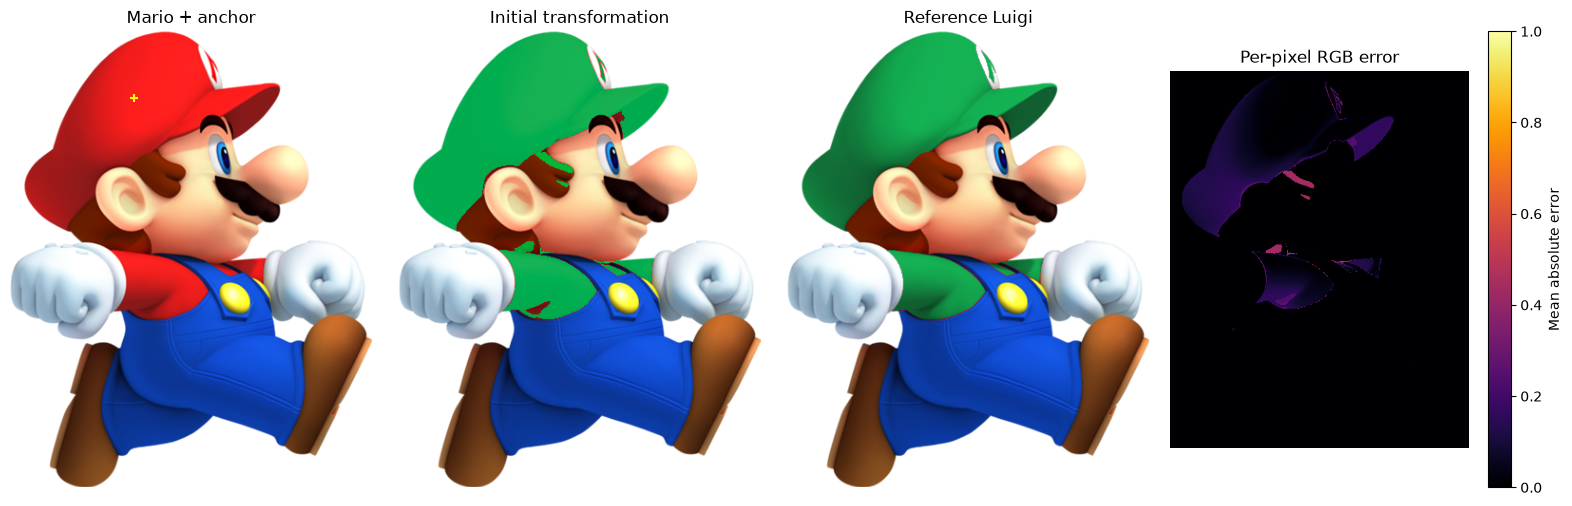

In [30]:
mario = plt.imread("mario.png")
target = plt.imread("luigi.png")

rgb = mario[:, :, :3]
target_rgb = target[:, :, :3]

# use the pixel at (70, 130)
row, col = 70, 130
red_anchor = rgb[row, col]
green_anchor = target_rgb[row, col]
shift = green_anchor - red_anchor

# detect 'red'
r, g, b = rgb[:, :, 0], rgb[:, :, 1], rgb[:, :, 2]
# I just ask codex for 'red' mask with RGB, with tight bound
# a few trial and error on the exact value of this mask
"""
mask = (
    (r > 1.5 * g) &
    (r > 1.5 * b) &
    (r - g > 0.25) &
    (g < 0.35) &
    (r > 0.3)
)

mask = (
    (r > 0.60) &
    (g < 0.18) &
    (b < 0.18) &
    (r > 4.0 * g) &
    (r > 4.0 * b)
)
"""
mask = (
    (r > 0.50) &
    (g < 0.25) &
    (b < 0.25) &
    (r > 3.0 * g) &
    (r > 3.0 * b)
)

result = mario.copy()
result_rgb = result[:, :, :3]
result_rgb[mask] = np.clip(rgb[mask] + shift, 0, 1)

# Compare our initial transformation with the reference.
transformed = result
title = "Initial transformation"

target = plt.imread("luigi.png")
target_rgb = target[:, :, :3]
error_map = np.mean(np.abs(transformed[:, :, :3] - target_rgb), axis=-1)
print(f"{title} — Mean absolute RGB error: {np.mean(error_map):.8f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(mario)
axes[0].scatter(col, row, c="yellow", marker="+")
axes[0].set_title("Mario + anchor")

axes[1].imshow(transformed)
axes[1].set_title(title)

axes[2].imshow(target)
axes[2].set_title("Reference Luigi")

heatmap = axes[3].imshow(error_map, cmap="inferno", vmin=0, vmax=1)
axes[3].set_title("Per-pixel RGB error")
fig.colorbar(heatmap, ax=axes[3], label="Mean absolute error")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


From the heat map, we see there's some error for 'red' masking, and even in area where the mask correctly identify 'red', the color shift to 'green' shill exhibit tonal difference compare to our reference image, so I supposed a constant shifting factor isn't the right tool here. I expect the proper implementation offered by the guide would perform better than this. 

### 5.1 Detecting Red Cloth

Remember from the class that the mario image is kept in array of rgba value. The alpha value doesn't contribute to the color. So, we can ignore that(for now).

To understand how this rgba value from his hat/cloth is different from the rest of images we will make some useful scatter plot. Hopefully pixel from his cloth will be clustered away from the rest.

5.1.1) Collecting samples. To do analysis on mario we need to collect some samples from his image.

In [31]:
mario = plt.imread('mario.png')

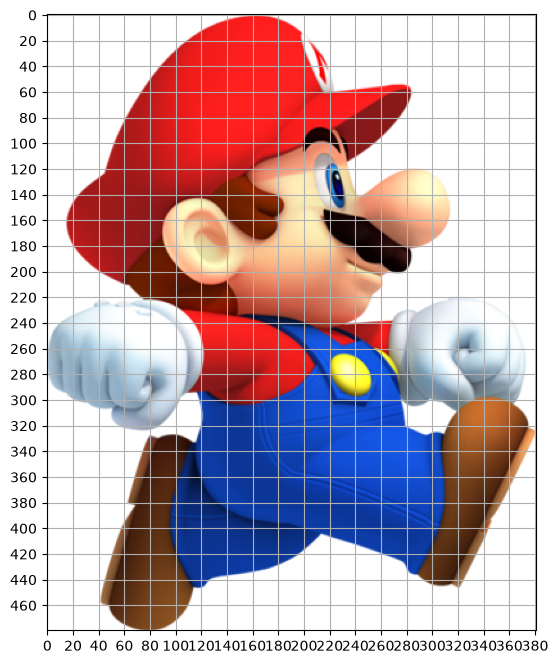

In [32]:
plt.figure(figsize=(8,8))
plt.imshow(mario)
plt.xticks(range(0,400,20))
plt.yticks(range(0,480,20))
plt.grid(True, 'both')

# Fill this out

In [33]:
hat = mario[60:80,180:200]
dark_hat = mario[80:90, 240:250]
# have kids fill some of this
hair = mario[135: 155, 140: 160]
shoe = mario[320: 340, 320: 340]
armpit = mario[280: 300, 140: 160]
right_arm = mario[240: 260, 140: 160]
left_arm = mario[241: 251, 241: 251]
dress = mario[320: 340, 180: 200]
cheek = mario[220: 230, 220: 230]
white_bg = mario[0: 20, 360: 380]

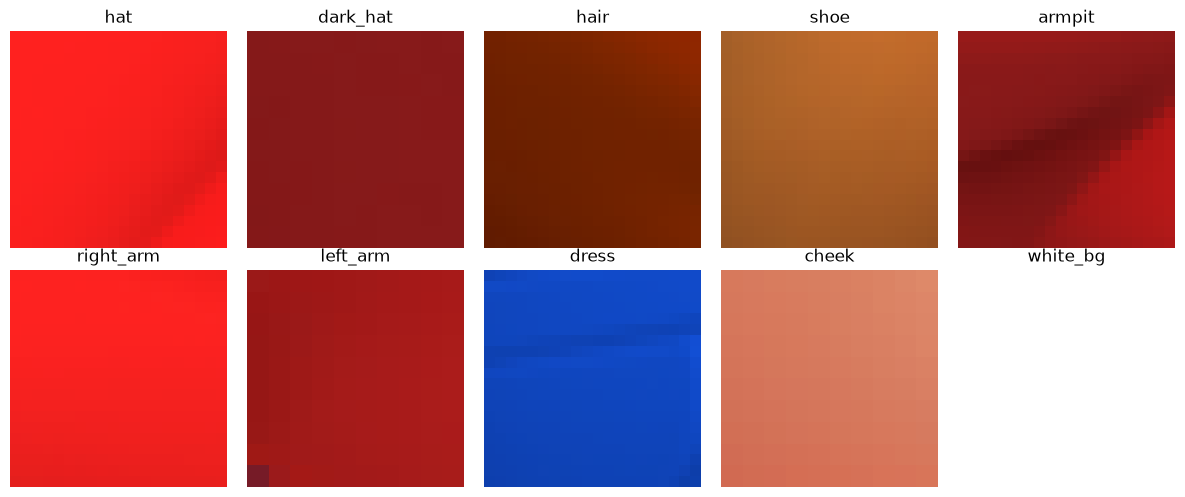

In [34]:
#plot to make sure you actually get the right part
# plt.imshow(hat)

samples = {
    "hat": hat,
    "dark_hat": dark_hat,
    "hair": hair,
    "shoe": shoe,
    "armpit": armpit,
    "right_arm": right_arm,
    "left_arm": left_arm,
    "dress": dress,
    "cheek": cheek,
    "white_bg": white_bg,
}

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, (name, block) in zip(axes.flat, samples.items()):
    ax.imshow(block)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [35]:
# define signal(red cloth/hat) and background(other stuff)
# signal and background is now just an array of shape (npixel, 3)
# this will make you life simpler when you analyze stuff
# print the shape to see what it looks like
def flat(p):
    return p.reshape(-1, p.shape[-1])
# (480, 381, 4) -> (182880, 4)

signal = np.concatenate((
    flat(hat),
    flat(dark_hat),
    flat(armpit),
    flat(right_arm),
    flat(left_arm)
))[:, :3] # remove the alpha channel

background = np.concatenate((
    flat(hair),
    flat(shoe),
    flat(dress),
    flat(cheek),
    flat(white_bg)
))[:, :3] # remove the alpha channel

5.1.2) Let's make some histogram of how R values differ between his red cloth and the rest.

Once you are done make a plot of B and G as well. I want you to make the following graph. Showing the difference in distribution of R value for signal and background.

![rgb_hist](rgb_hist.png)

Look for: `plt.subplots` and `plt.hist` and figure out what `signal[:,2]` does.

Each sampled block gets equal weight within its group, regardless of its pixel count. Each pixel in a block receives weight `1 / (number_of_blocks * pixels_in_block)`, so the signal and background histograms each sum to 1. This prevents the larger blocks from dominating the comparison. All plots use the same bins over [0, 1].


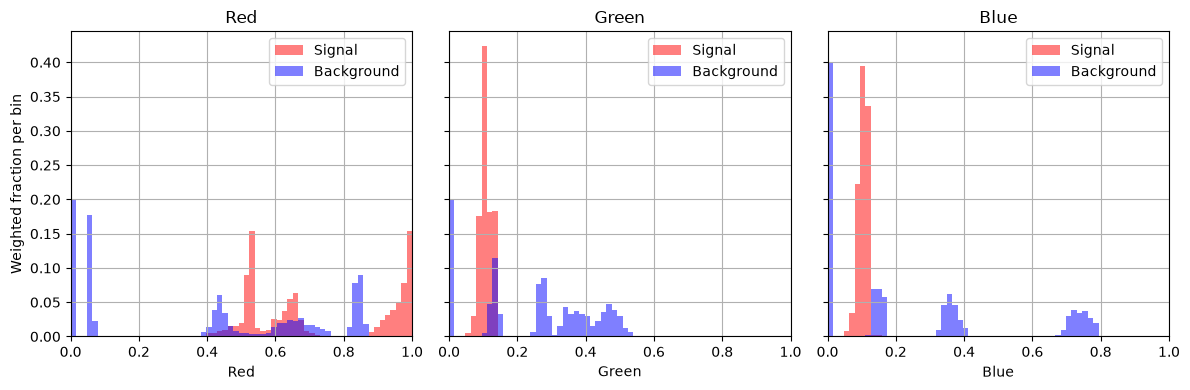

In [36]:
signal_blocks = [hat, dark_hat, armpit, right_arm, left_arm]
background_blocks = [hair, shoe, dress, cheek, white_bg]

def block_weights(blocks):
    weights = []

    for block in blocks:
        pixel_count = flat(block).shape[0]
        weight_per_pixel = 1 / (len(blocks) * pixel_count)
        weights.extend([weight_per_pixel] * pixel_count)

    return weights

signal_weights = block_weights(signal_blocks)
background_weights = block_weights(background_blocks)

bins = np.linspace(0, 1, 1 << 6)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

axes[0].hist(signal[:, 0], bins=bins, weights=signal_weights,
             color="red", alpha=0.5, label="Signal")
axes[0].hist(background[:, 0], bins=bins, weights=background_weights,
             color="blue", alpha=0.5, label="Background")
axes[0].set_title("Red")
axes[0].set_xlabel("Red")
axes[0].set_xlim(0, 1)
axes[0].grid()
axes[0].legend()

axes[1].hist(signal[:, 1], bins=bins, weights=signal_weights,
             color="red", alpha=0.5, label="Signal")
axes[1].hist(background[:, 1], bins=bins, weights=background_weights,
             color="blue", alpha=0.5, label="Background")
axes[1].set_title("Green")
axes[1].set_xlabel("Green")
axes[1].set_xlim(0, 1)
axes[1].grid()
axes[1].legend()

axes[2].hist(signal[:, 2], bins=bins, weights=signal_weights,
             color="red", alpha=0.5, label="Signal")
axes[2].hist(background[:, 2], bins=bins, weights=background_weights,
             color="blue", alpha=0.5, label="Background")
axes[2].set_title("Blue")
axes[2].set_xlabel("Blue")
axes[2].set_xlim(0, 1)
axes[2].grid()
axes[2].legend()

axes[0].set_ylabel("Weighted fraction per bin")
plt.tight_layout()
plt.show()


5.1.3) From the graph you made, which color is a good choice for separting his red hat/cloth from the rest? You may be surprised.

'green' and 'blue', at (0.025, 0.2), where the weight is over 0.15 and 0.1 successively. 

5.1.4) We can do better than 1d plot. We can do 2d scatter plot. Make the following plot which show how 2-d distribution of each feature pair (eg: (R,B)) differs between signal and the background.
![rgb_scatter](rgb_scatter.png)

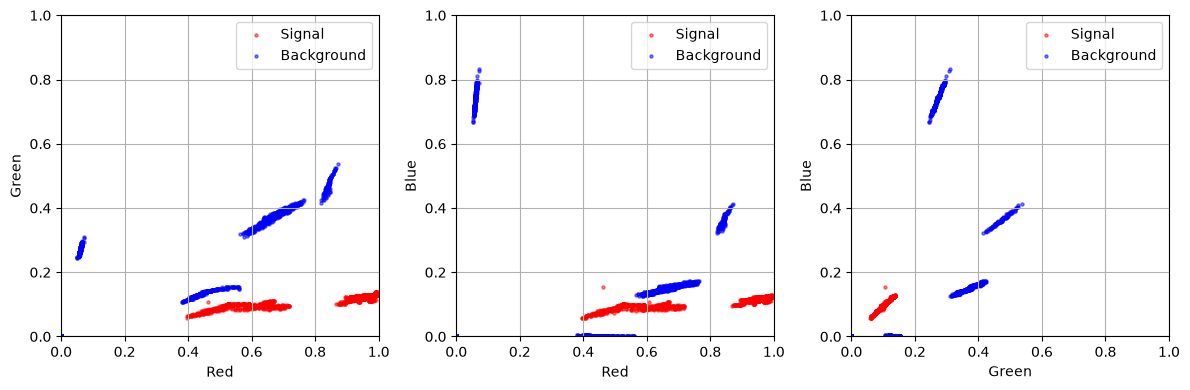

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].scatter(signal[:, 0], signal[:, 1],
                color="red", s=5, alpha=0.5, label="Signal")
axes[0].scatter(background[:, 0], background[:, 1],
                color="blue", s=5, alpha=0.5, label="Background")
axes[0].set_xlabel("Red")
axes[0].set_ylabel("Green")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].grid()
axes[0].legend()

axes[1].scatter(signal[:, 0], signal[:, 2],
                color="red", s=5, alpha=0.5, label="Signal")
axes[1].scatter(background[:, 0], background[:, 2],
                color="blue", s=5, alpha=0.5, label="Background")
axes[1].set_xlabel("Red")
axes[1].set_ylabel("Blue")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].grid()
axes[1].legend()

axes[2].scatter(signal[:, 1], signal[:, 2],
                color="red", s=5, alpha=0.5, label="Signal")
axes[2].scatter(background[:, 1], background[:, 2],
                color="blue", s=5, alpha=0.5, label="Background")
axes[2].set_xlabel("Green")
axes[2].set_ylabel("Blue")
axes[2].set_xlim(0, 1)
axes[2].set_ylim(0, 1)
axes[2].grid()
axes[2].legend()

plt.tight_layout()
plt.show()


### What we learned so far.


We learned a lot by making the right kind of visualization. We can see clearly that the signal shown in red is clearly seperated from the background(blue). We could in principle end it here by drawing a straight line on (R-G) space which seperate the two. Finding that equation and figure out how to calculate if a point is on the right or on the left of the line. You would even learn a more sophisticated method in Pattern Recognition on how to teach computer to seperate the two groups. But, we will not do it here. 

### Better Color Space

We will make the problem much much easier by using the "right" kind of color space which are different kind of representing color. Some popular ones are(google up if you are interested)
  - RGB which we were using. This representation of color makes sense for computer screen and such since it use red green and blue pixel to represent color
  - CYMK. Ever notice that printer ink are actually not Red Green Blue? They are Cyan, Yellow, Magenta, and blacK? this is used primarily for printing purposes. Printing Graphic Designer goes through a great ordeal to match their screen color(in RGB) with one they will see in printing(CMYK).
  - HSV or HSL. Hue Saturation and Value/Lightness. The is what we are going to be using. It seperate the color(Hue), Saturation and Value. https://en.wikipedia.org/wiki/HSL_and_HSV. This color space closely match on how human perceive color. Typically, it's the right choice when doing image analysis.
  
<img src="HSV_color_solid_cylinder.png" style="height:200px;"/>

5.1.3) **Convert signal and background to hsv.** For this task conver signal array and background array to hsv instead of hsv.
Luckily we do not have to implement the conversion between RGB and HSV since matplotlib already has it for it. See `matplotlib.colors.rgb_to_hsv` and `matplotlib.colors.hsv_to_rgb`.

The answer should be one line each for signal_hsv and background_hsv. Read up the manual

In [38]:
import matplotlib

signal_hsv = matplotlib.colors.rgb_to_hsv(signal)
background_hsv = matplotlib.colors.rgb_to_hsv(background)


5.1.4) Let's make the histogram to see how Hue, Saturation, and Value are distributed differently among signal and background.

![hsv_hist](hsv_hist.png)

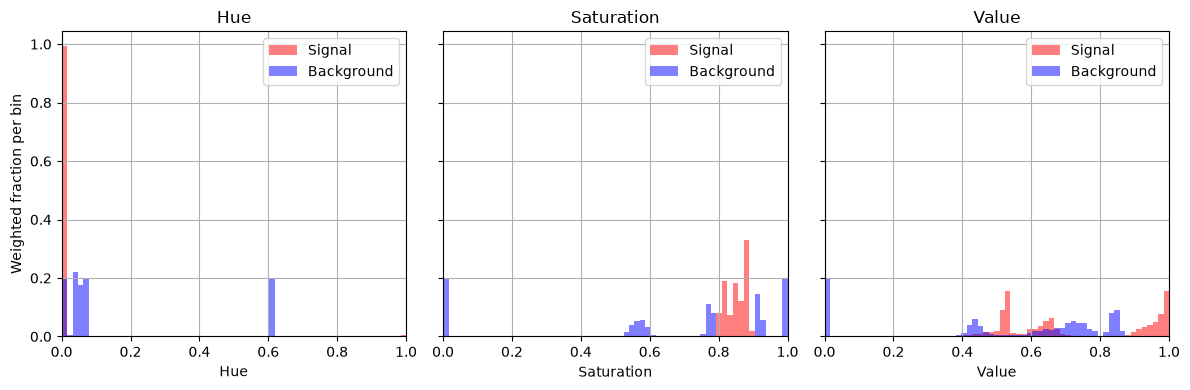

In [39]:
bins = np.linspace(0, 1, 1 << 6)
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

axes[0].hist(signal_hsv[:, 0], bins=bins, weights=signal_weights,
             color="red", alpha=0.5, label="Signal")
axes[0].hist(background_hsv[:, 0], bins=bins, weights=background_weights,
             color="blue", alpha=0.5, label="Background")
axes[0].set_title("Hue")
axes[0].set_xlabel("Hue")
axes[0].set_xlim(0, 1)
axes[0].grid()
axes[0].legend()

axes[1].hist(signal_hsv[:, 1], bins=bins, weights=signal_weights,
             color="red", alpha=0.5, label="Signal")
axes[1].hist(background_hsv[:, 1], bins=bins, weights=background_weights,
             color="blue", alpha=0.5, label="Background")
axes[1].set_title("Saturation")
axes[1].set_xlabel("Saturation")
axes[1].set_xlim(0, 1)
axes[1].grid()
axes[1].legend()

axes[2].hist(signal_hsv[:, 2], bins=bins, weights=signal_weights,
             color="red", alpha=0.5, label="Signal")
axes[2].hist(background_hsv[:, 2], bins=bins, weights=background_weights,
             color="blue", alpha=0.5, label="Background")
axes[2].set_title("Value")
axes[2].set_xlabel("Value")
axes[2].set_xlim(0, 1)
axes[2].grid()
axes[2].legend()

axes[0].set_ylabel("Weighted fraction per bin")
plt.tight_layout()
plt.show()


5.1.5) While we are at it let's make a 2-D scatter plot. Like this one
![hsv_scatter](hsv_scatter.png)

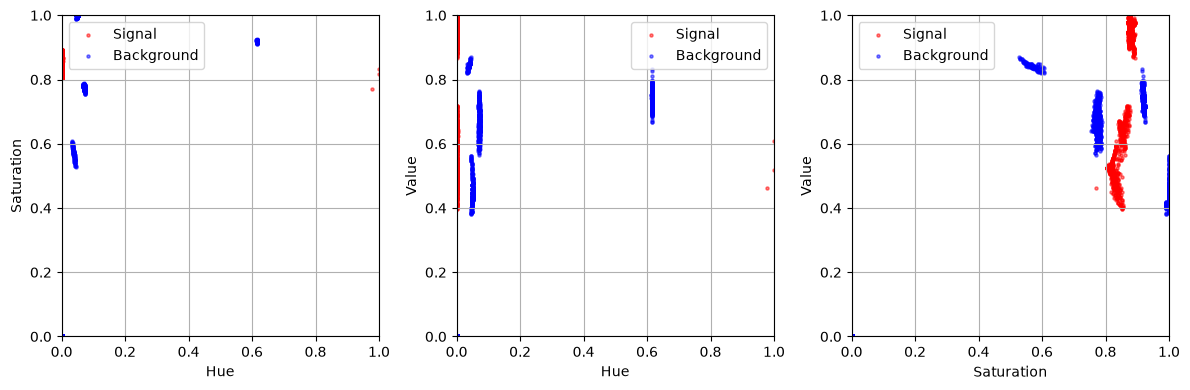

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].scatter(signal_hsv[:, 0], signal_hsv[:, 1],
                color="red", s=5, alpha=0.5, label="Signal")
axes[0].scatter(background_hsv[:, 0], background_hsv[:, 1],
                color="blue", s=5, alpha=0.5, label="Background")
axes[0].set_xlabel("Hue")
axes[0].set_ylabel("Saturation")
axes[0].set_xlim(0, 1)
axes[0].set_ylim(0, 1)
axes[0].grid()
axes[0].legend()

axes[1].scatter(signal_hsv[:, 0], signal_hsv[:, 2],
                color="red", s=5, alpha=0.5, label="Signal")
axes[1].scatter(background_hsv[:, 0], background_hsv[:, 2],
                color="blue", s=5, alpha=0.5, label="Background")
axes[1].set_xlabel("Hue")
axes[1].set_ylabel("Value")
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].grid()
axes[1].legend()

axes[2].scatter(signal_hsv[:, 1], signal_hsv[:, 2],
                color="red", s=5, alpha=0.5, label="Signal")
axes[2].scatter(background_hsv[:, 1], background_hsv[:, 2],
                color="blue", s=5, alpha=0.5, label="Background")
axes[2].set_xlabel("Saturation")
axes[2].set_ylabel("Value")
axes[2].set_xlim(0, 1)
axes[2].set_ylim(0, 1)
axes[2].grid()
axes[2].legend()

plt.tight_layout()
plt.show()


5.1.6) There is one technical difficulty. You may notice some points at $h=1.0$. 

The hue value is essentially the angle so it wraps around. This means that 0 is actully close to 1.

<img src="HSV_color_solid_cylinder.png" style="width:200px"/>

Your job for this one is to write a function called `hue_distance(h1, h2)` to calculate how far the two hues are given the fact that it wraps around.

Do not think too much it's just one `if`.

 - `hue_distance(1.0,0.0) == 0.0`
 - `hue_distance(0.0,0.2) == 0.2`
 - `hue_distance(0.5,0.2) == 0.3`

In [41]:
def hue_distance(h1, h2):
    distance = abs(h1 % 1.0 - h2 % 1.0)
    return np.minimum(distance, 1.0 - distance)

assert hue_distance(1.0, 0.0) == 0.0
assert hue_distance(0.0, 0.2) == 0.2
assert hue_distance(0.5, 0.2) == 0.3

5.1.7) Use what you learned from HSV plots and find write a code that seperate the red hat/cloth and the rest. Zoom in the plots you made if needed. If there are regions that doesn't work as you expect add it to the sample and modify your condition rinse and repeat.

With the two plots I managed to get this
<img src="mask.png"/>

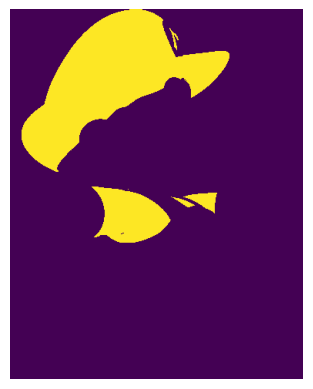

In [42]:
mario_hsv = matplotlib.colors.rgb_to_hsv(mario[:, :, :3])

h = mario_hsv[:, :, 0]
s = mario_hsv[:, :, 1]
v = mario_hsv[:, :, 2]

mask = (
    (hue_distance(h, 0.0) < 0.01)
    & (s > 0.7)
    & (v > 0.4)
)

plt.imshow(mask)
plt.axis("off")
plt.show()

### 5.2) Changing Color Without Chaning The Shade

Now that we can detect Mario's cloth. All we need to do now is to change the color of his cloth to "green" ish. This means that all we need to do is to change the hue value from red hue to green hue.

The hue value can be found below. Make sure you divide it by 360 to get it to 0-1 range that matplotlib expect.

<img src="YOBFy.png" style="height:50px"/>

***Your task*** Make `luigi.png`

<img src="luigi.png" style="height:100px"/>

Hint:
  - You will want to convert hsv back to rgb and pad the original alpha backin so you can display it nicely with `imshow`
  - `matplotlib.colors.hsv_to_rgb` is handy.
  - you can copy nparray with `nparray.copy()`
  - if you want a darker shade scale `value` component down a little bit.




In [43]:
matplotlib.colors.rgb_to_hsv(target[70, 130, :3])

array([0.39957264, 0.8863636 , 0.6901961 ], dtype=float32)

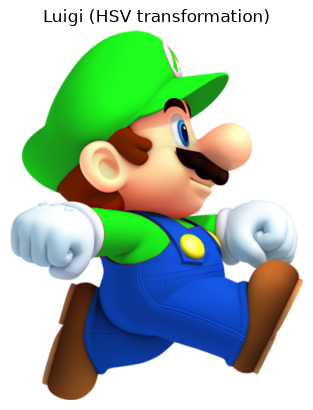

In [44]:
luigi_hsv = mario_hsv.copy()
luigi_hsv[mask, 0] = 120 / 360  # 0.33333334
                                
luigi_rgb = matplotlib.colors.hsv_to_rgb(luigi_hsv)
luigi = mario.copy()
luigi[mask, :3] = luigi_rgb[mask]  # keep other pixels and original alpha

plt.imshow(luigi)
plt.title("Luigi (HSV transformation)")
plt.axis("off")
plt.show()

if we only apply the 'hue' value, the result luiji will be quite brighter than our control, so we have to find the optimal 'value'

In [45]:
matplotlib.colors.rgb_to_hsv(target[70, 130, :3]) / matplotlib.colors.rgb_to_hsv(mario[70, 130, :3])

array([534.62823  ,   1.0016307,   0.6984127], dtype=float32)

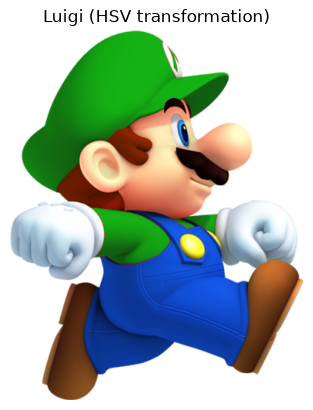

In [46]:
luigi_hsv = mario_hsv.copy()
luigi_hsv[mask, 0] = 120 / 360  # 0.33333334
luigi_hsv[mask, 1] = np.minimum(luigi_hsv[mask, 1] * 1.0016307, 1.0)
luigi_hsv[mask, 2] *= 0.6984127
                                
luigi_rgb = matplotlib.colors.hsv_to_rgb(luigi_hsv)
luigi = mario.copy()
luigi[mask, :3] = luigi_rgb[mask]  # keep other pixels and original alpha

plt.imshow(luigi)
plt.title("Luigi (HSV transformation)")
plt.axis("off")
plt.show()

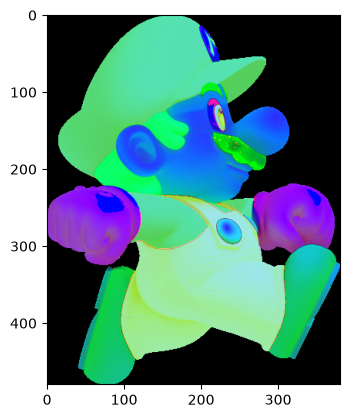

In [47]:
plt.imshow(luigi_hsv)

HSV transformation — Mean absolute RGB error: 0.01137761


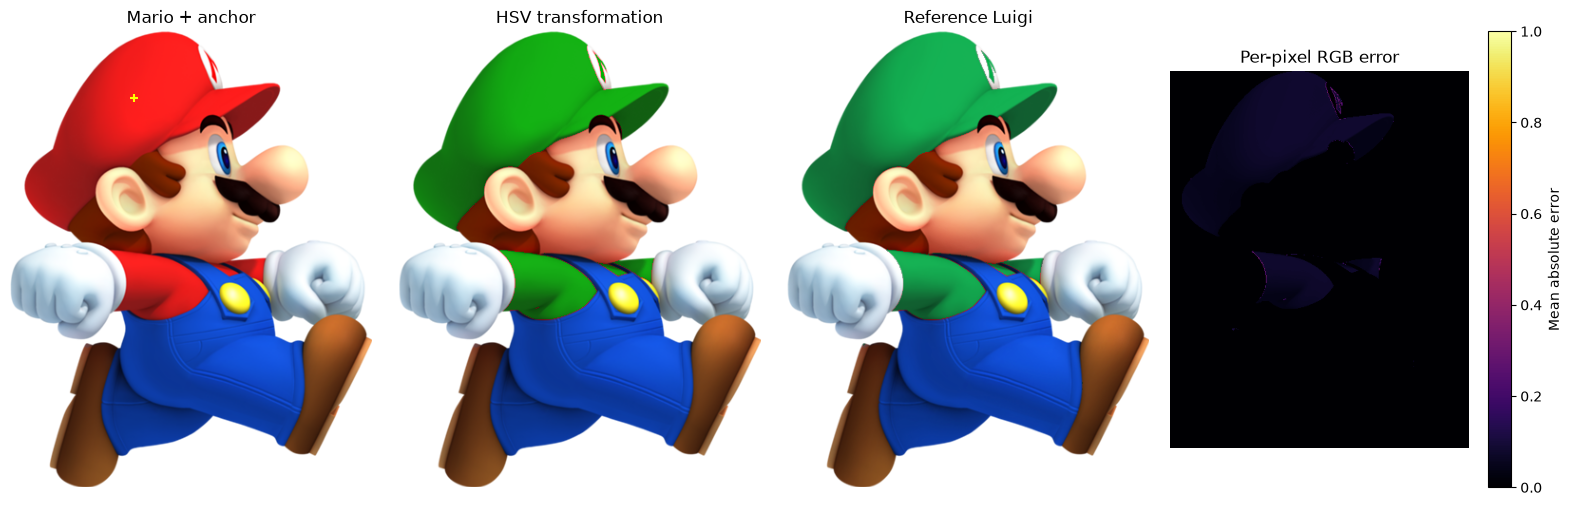

In [48]:
transformed = luigi
title = "HSV transformation"

target = plt.imread("luigi.png")
target_rgb = target[:, :, :3]
error_map = np.mean(np.abs(transformed[:, :, :3] - target_rgb), axis=-1)
print(f"{title} — Mean absolute RGB error: {np.mean(error_map):.8f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(mario)
axes[0].scatter(col, row, c="yellow", marker="+")
axes[0].set_title("Mario + anchor")

axes[1].imshow(transformed)
axes[1].set_title(title)

axes[2].imshow(target)
axes[2].set_title("Reference Luigi")

heatmap = axes[3].imshow(error_map, cmap="inferno", vmin=0, vmax=1)
axes[3].set_title("Per-pixel RGB error")
fig.colorbar(heatmap, ax=axes[3], label="Mean absolute error")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

the result isn't a perfect transformation, there still some difference of our result to the reference image, but it's noticeably better than our initial approach, especially in the 'green' masking part. 

Ps. I think i should mention that the plotting parts is heavily assisted by GPT-6-Astra via codex.

---